In [1]:
import numpy as np
import pandas as pd
import datetime
import matplotlib.pyplot as plt
import seaborn as sns
bike=pd.read_csv('bike.csv')
bike.head()

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1


In [2]:
bike.info()

<class 'pandas.DataFrame'>
RangeIndex: 10886 entries, 0 to 10885
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   datetime    10886 non-null  str    
 1   season      10886 non-null  int64  
 2   holiday     10886 non-null  int64  
 3   workingday  10886 non-null  int64  
 4   weather     10886 non-null  int64  
 5   temp        10886 non-null  float64
 6   atemp       10886 non-null  float64
 7   humidity    10886 non-null  int64  
 8   windspeed   10886 non-null  float64
 9   casual      10886 non-null  int64  
 10  registered  10886 non-null  int64  
 11  count       10886 non-null  int64  
dtypes: float64(3), int64(8), str(1)
memory usage: 1020.7 KB


In [3]:
bike.datetime=pd.to_datetime(bike.datetime)
bike.dtypes

datetime      datetime64[us]
season                 int64
holiday                int64
workingday             int64
weather                int64
temp                 float64
atemp                float64
humidity               int64
windspeed            float64
casual                 int64
registered             int64
count                  int64
dtype: object

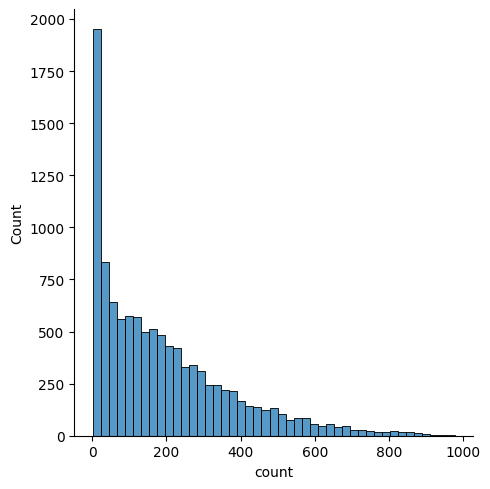

In [4]:
bike=bike.set_index('datetime')
sns.displot(bike['count'])

In [5]:
bike['count'].describe()

count    10886.000000
mean       191.574132
std        181.144454
min          1.000000
25%         42.000000
50%        145.000000
75%        284.000000
max        977.000000
Name: count, dtype: float64

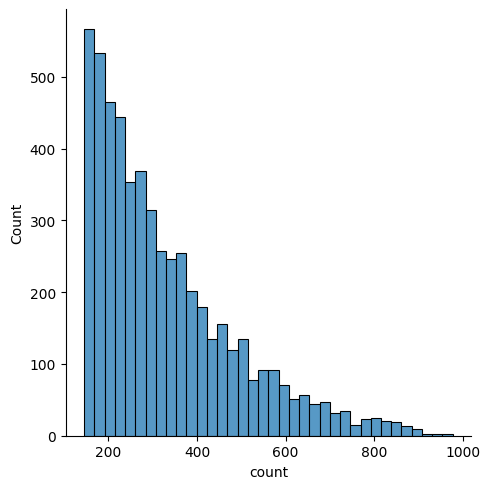

In [8]:
def Count(x):
    if x<145:
        return np.nan
    else:
        return x
bike1=bike
bike1['count']=bike1['count'].apply(Count)
bike1=bike1.dropna(axis=0,how='any')
sns.displot(bike1['count'])

In [9]:
bike=bike1
ybike=bike.groupby(bike.index.year).mean()['count']
ybike

datetime
2011    274.526697
2012    366.408629
Name: count, dtype: float64

<Axes: xlabel='datetime'>

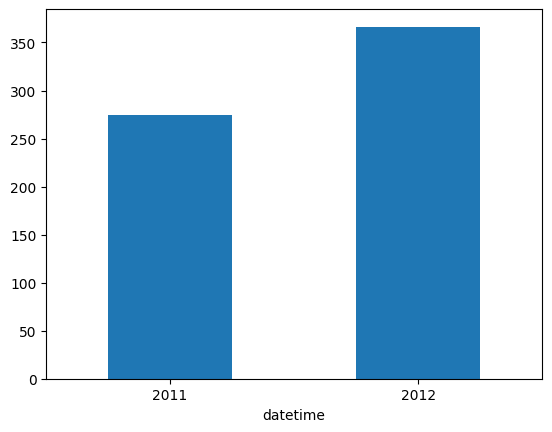

In [10]:
ybike.plot(kind='bar',rot=0)

In [14]:
mmbike = bike.resample('ME').mean().to_period('M')
mmbike.head(10)

,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
datetime,,,,,,,,,,,
2011-01,1.0,0.000000,1.000000,1.160000,8.692000,10.909600,49.320000,11.880440,5.280000,175.520000,180.800000
2011-02,1.0,0.000000,0.791045,1.283582,14.294925,17.243134,44.179104,18.179100,23.835821,168.208955,192.044776
2011-03,1.0,0.000000,0.666667,1.291667,16.553750,19.728021,49.458333,18.187778,48.583333,163.781250,212.364583
2011-04,2.0,0.078014,0.617021,1.453901,19.970780,23.634752,55.177305,16.893741,60.624113,177.539007,238.163121
2011-05,2.0,0.000000,0.758197,1.446721,23.060820,27.214037,64.069672,13.946627,55.745902,224.110656,279.856557
2011-06,2.0,0.000000,0.692593,1.322222,29.410667,33.319630,51.774074,12.844570,64.659259,229.333333,293.992593
2011-07,3.0,0.052632,0.616541,1.161654,31.304887,35.264624,53.646617,13.537803,86.962406,218.849624,305.812030
2011-08,3.0,0.000000,0.807843,1.290196,30.973490,34.795275,55.388235,14.298194,59.368627,222.450980,281.819608
2011-09,3.0,0.039130,0.613043,1.508696,26.282783,30.112630,67.604348,11.982892,69.530435,220.782609,290.313043


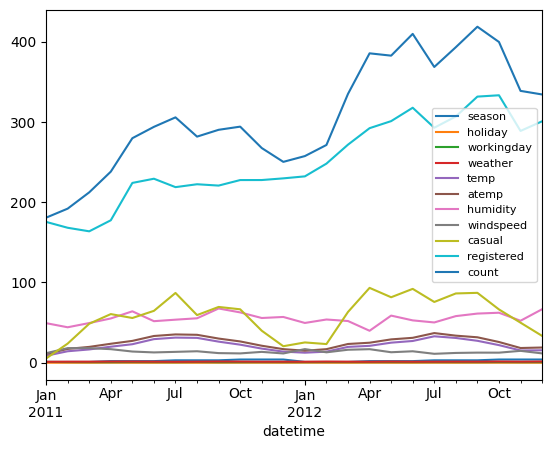

In [15]:
mmbike.plot()
plt.legend(loc='best',fontsize=8)

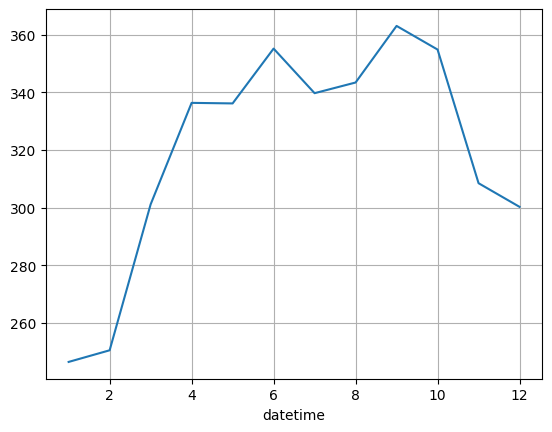

In [16]:
mbike=bike.groupby(bike.index.month).mean()['count']
mbike.plot()
plt.grid()

<Axes: xlabel='datetime'>

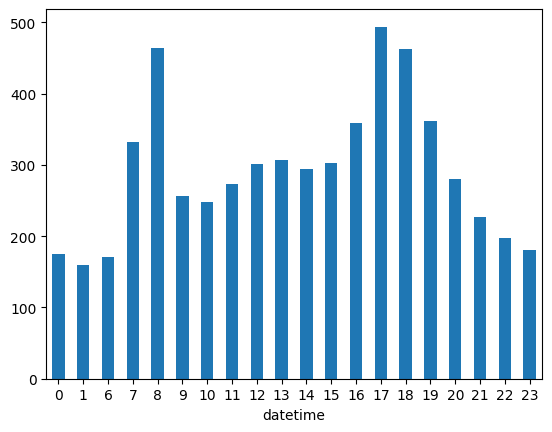

In [18]:
hbike=bike.groupby(bike.index.hour).mean()['count']
hbike.plot(kind='bar',rot=0)

<Axes: xlabel='weather'>

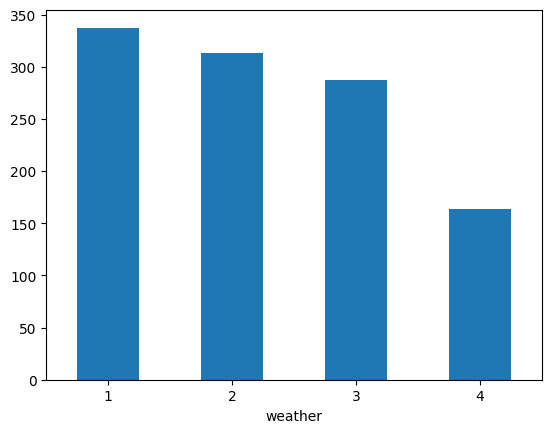

In [19]:
wbike=bike.groupby(bike.weather).mean()['count']
wbike.plot(kind='bar',rot=0)